In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

# Load cleaned sales data
sales_df = pd.read_excel(
    "Sales_Performance_Dataset.xlsx",
    sheet_name="Sales_Cleaned"
)

# Load customer master data
customers_df = pd.read_excel(
    "Sales_Performance_Dataset.xlsx",
    sheet_name="Customers_Master"
)

print("Sales Data Shape:", sales_df.shape)
print("Customer Data Shape:", customers_df.shape)

display(sales_df.head())
display(customers_df.head())

Sales Data Shape: (12000, 22)
Customer Data Shape: (2500, 5)


,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Salesperson,Sales_Channel,Payment_Method,Quantity,...,Discount_Amount,Revenue,Calculated_Revenue,Revenue_Check,Cost,Profit,Calculated_Profit,Profit_Check,Order_Status,City
0,ORD108215,2025-01-10,CUST12432,Desk,Furniture,East,Salesperson_1,Partner,Debit Card,2,...,4956.93,19827.73,19827.73,Ok,16367.54,3460.19,3460.19,Ok,Delivered,Ahmedabad
1,ORD107332,2025-01-17,CUST12432,Power Bank,Accessories,North,Salesperson_1,Online,UPI,1,...,172.68,1554.12,1554.12,Ok,1238.75,315.37,315.37,Ok,Delivered,Ahmedabad
2,ORD106406,2025-02-05,CUST11965,Smartphone,Electronics,South,Salesperson_1,Retail Store,Credit Card,2,...,0.00,55776.48,55776.48,Ok,40529.05,15247.43,15247.43,Ok,Delivered,Ahmedabad
3,ORD104247,2025-02-12,CUST11730,Backpack,Lifestyle,West,Salesperson_1,Retail Store,Credit Card,2,...,433.97,3905.69,3905.69,Ok,3326.43,579.26,579.26,Ok,Delivered,Ahmedabad
4,ORD104007,2025-02-13,CUST10806,Power Bank,Accessories,North,Salesperson_1,Online,Credit Card,1,...,201.52,1813.67,1813.67,Ok,1509.05,304.62,304.62,Ok,Delivered,Ahmedabad


,Customer_ID,Customer_Name,Gender,City,Customer_Tier
0,CUST10001,Customer_0001,Male,Navi Mumbai,Bronze
1,CUST10002,Customer_0002,Female,Thane,Gold
2,CUST10003,Customer_0003,Female,Hyderabad,Bronze
3,CUST10004,Customer_0004,Female,Navi Mumbai,Gold
4,CUST10005,Customer_0005,Male,Kolkata,Gold


In [3]:
# Check cleaned data
print("Sales Data Shape:", sales_df.shape)
print("Missing Values:", sales_df.isnull().sum().sum())
print("Duplicate Rows:", sales_df.duplicated().sum())

Sales Data Shape: (12000, 22)
Missing Values: 0
Duplicate Rows: 0


In [4]:

# Customer-wise purchase analysis

customer_analysis = (
    sales_df.groupby("Customer_ID")
    .agg(
        Total_Spending=("Revenue", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Average spending per order
customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Spending"]
    / customer_analysis["Total_Orders"]
)

# Display top 10 customers by spending
top_10_customers = customer_analysis.sort_values(
    "Total_Spending", ascending=False
).head(10)

display(top_10_customers.round(2))


,Customer_ID,Total_Spending,Total_Orders,Total_Quantity,Average_Order_Value
1276,CUST11285,796817.45,11,29,72437.95
2279,CUST12293,753943.29,7,21,107706.18
1111,CUST11117,676965.80,10,32,67696.58
867,CUST10871,620322.53,9,27,68924.73
1336,CUST11345,605429.34,7,27,86489.91
36,CUST10037,580675.49,8,25,72584.44
1929,CUST11941,574161.66,6,19,95693.61
11,CUST10012,550639.52,10,32,55063.95
2320,CUST12334,538904.13,5,17,107780.83
2102,CUST12115,517383.90,9,24,57487.10


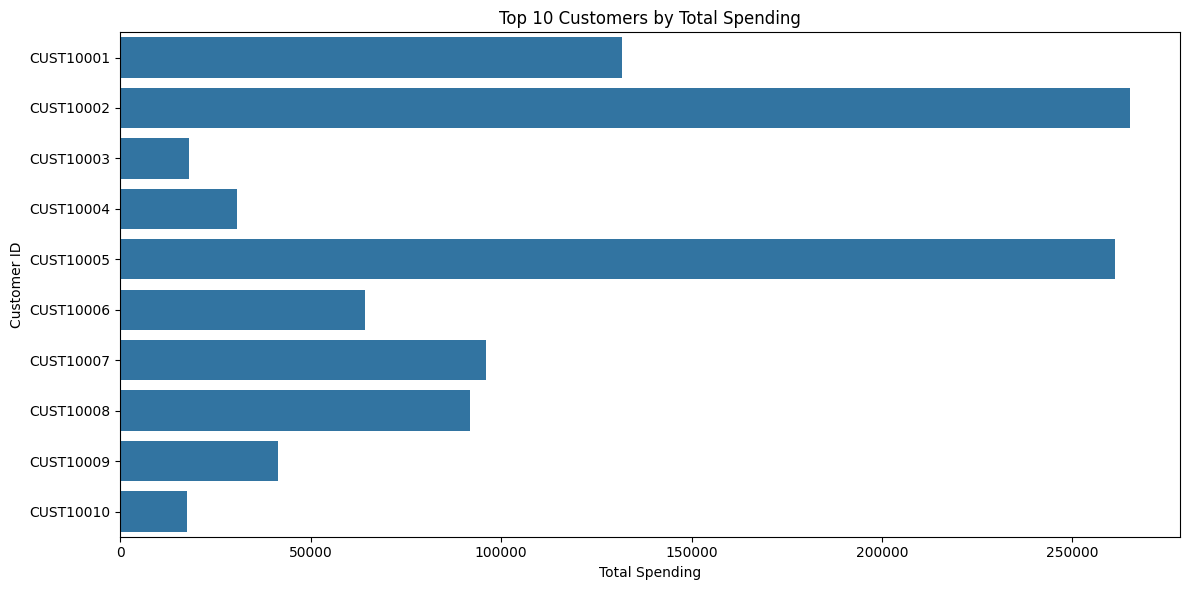

In [5]:

top_10_customers = customer_analysis.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10_customers,
    x="Total_Spending",
    y="Customer_ID"
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


,Product,Total_Revenue,Total_Quantity,Total_Orders
9,Power Bank,3112741.06,1911,870
13,Smartwatch,11976751.27,1887,852
0,Backpack,3764905.88,1883,840
3,Headphones,5918063.85,1866,821
5,Laptop,91114083.13,1823,790
4,Keyboard,2916957.18,1803,805
14,Tablet,35274325.78,1794,807
11,Router,6837254.54,1790,800
12,Smartphone,45019338.70,1772,778
1,Desk,19168833.68,1765,767


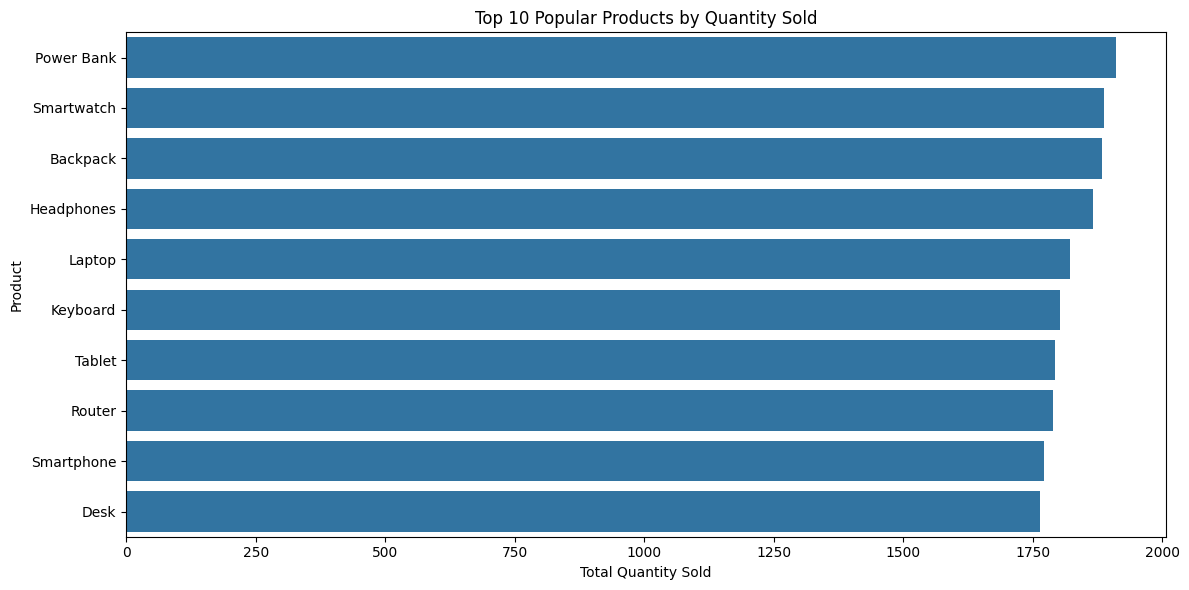

In [6]:

product_analysis = (
    sales_df.groupby("Product")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Quantity", ascending=False)
)

display(product_analysis.head(10).round(2))

plt.figure(figsize=(12, 6))
sns.barplot(
    data=product_analysis.head(10),
    x="Total_Quantity",
    y="Product"
)

plt.title("Top 10 Popular Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


,Year_Month,Total_Revenue,Total_Orders,Total_Quantity,Unique_Customers
0,2025-01,16509698.75,627,1419,554
1,2025-02,13517763.87,550,1231,489
2,2025-03,15787419.11,642,1457,566
3,2025-04,14053523.32,570,1242,503
4,2025-05,13362112.36,580,1275,533
5,2025-06,14266848.67,594,1312,527
6,2025-07,13583520.22,586,1244,514
7,2025-08,16808932.07,627,1428,552
8,2025-09,15207492.23,630,1486,558
9,2025-10,14324889.83,597,1330,538


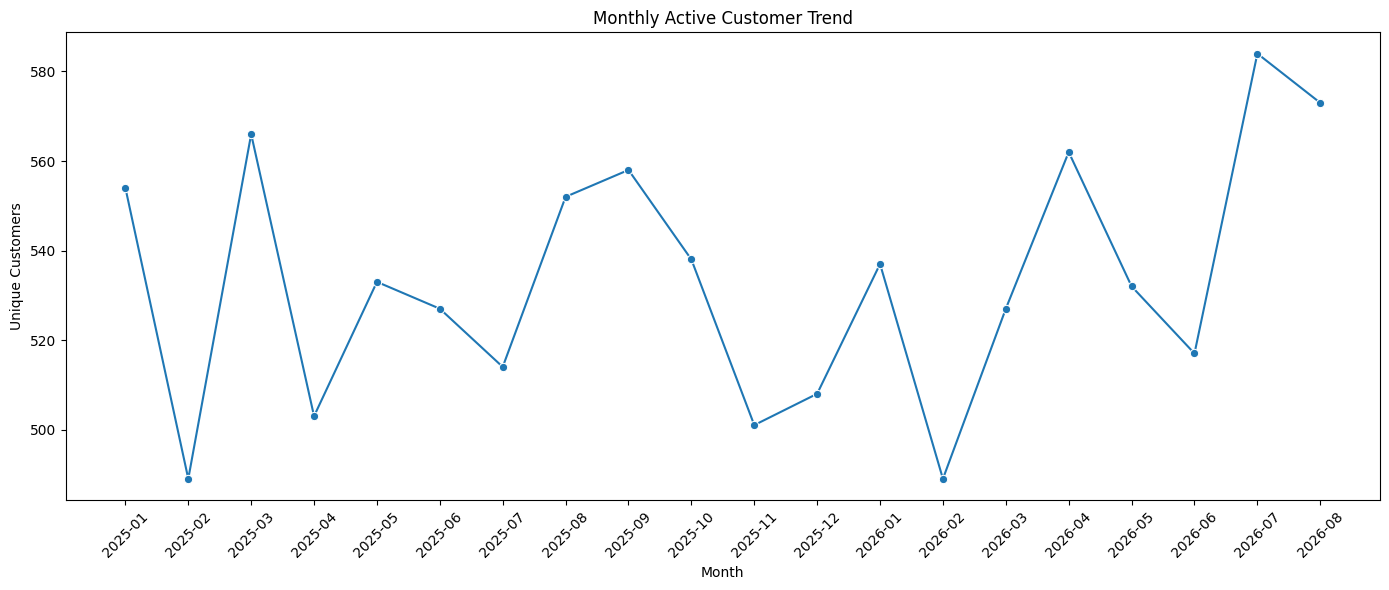

In [7]:

sales_df["Year_Month"] = (
    sales_df["Order_Date"].dt.to_period("M").astype(str)
)

monthly_analysis = (
    sales_df.groupby("Year_Month")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Customers=("Customer_ID", "nunique")
    )
    .reset_index()
)

display(monthly_analysis)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_analysis,
    x="Year_Month",
    y="Unique_Customers",
    marker="o"
)

plt.title("Monthly Active Customer Trend")
plt.xlabel("Month")
plt.ylabel("Unique Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Year_Month,Total_Revenue,Total_Orders,Total_Quantity,Unique_Customers
0,2025-01,16509698.75,627,1419,554
1,2025-02,13517763.87,550,1231,489
2,2025-03,15787419.11,642,1457,566
3,2025-04,14053523.32,570,1242,503
4,2025-05,13362112.36,580,1275,533
5,2025-06,14266848.67,594,1312,527
6,2025-07,13583520.22,586,1244,514
7,2025-08,16808932.07,627,1428,552
8,2025-09,15207492.23,630,1486,558
9,2025-10,14324889.83,597,1330,538


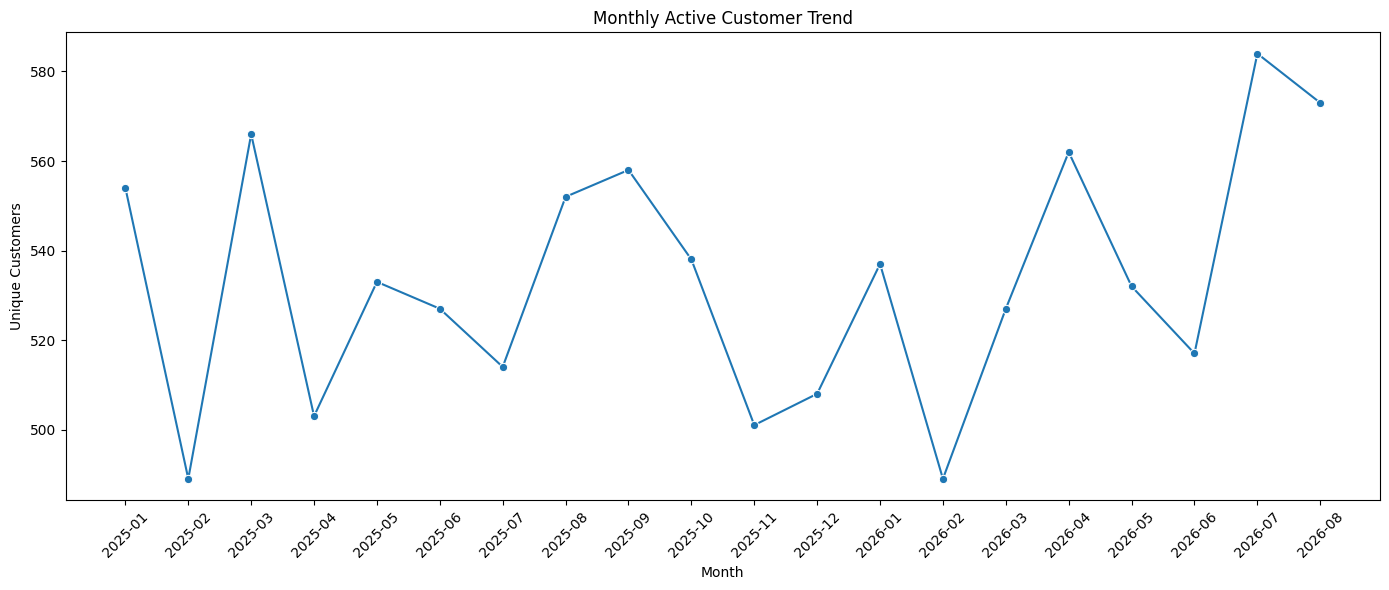

In [8]:

sales_df["Year_Month"] = (
    sales_df["Order_Date"].dt.to_period("M").astype(str)
)

monthly_analysis = (
    sales_df.groupby("Year_Month")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Customers=("Customer_ID", "nunique")
    )
    .reset_index()
)

display(monthly_analysis)

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_analysis,
    x="Year_Month",
    y="Unique_Customers",
    marker="o"
)

plt.title("Monthly Active Customer Trend")
plt.xlabel("Month")
plt.ylabel("Unique Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Number_of_Orders,Number_of_Customers
0,1,95
1,2,243
2,3,357
3,4,515
4,5,404
5,6,357
6,7,238
7,8,134
8,9,77
9,10,40


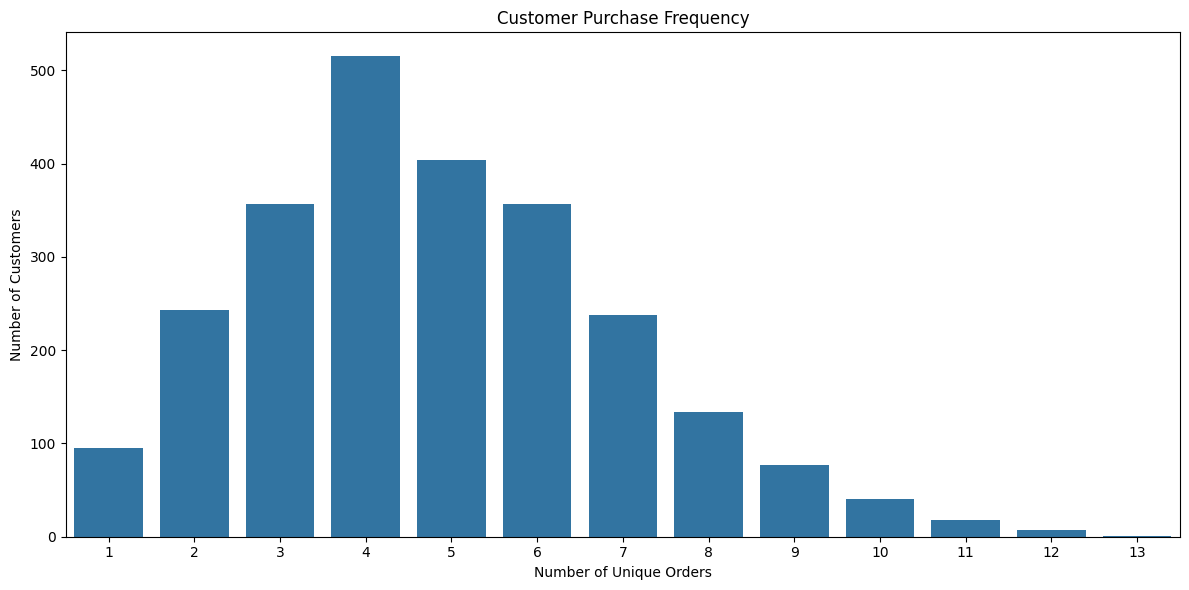

In [9]:

frequency_analysis = (
    customer_analysis["Total_Orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

frequency_analysis.columns = ["Number_of_Orders", "Number_of_Customers"]

display(frequency_analysis)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=frequency_analysis,
    x="Number_of_Orders",
    y="Number_of_Customers"
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Unique Orders")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


,Spending_Segment,Number_of_Customers,Total_Spending,Average_Spending
0,Low Spending,829,2.940111e+07,35465.76
1,Medium Spending,828,7.939557e+07,95888.38
2,High Spending,829,1.895883e+08,228695.21


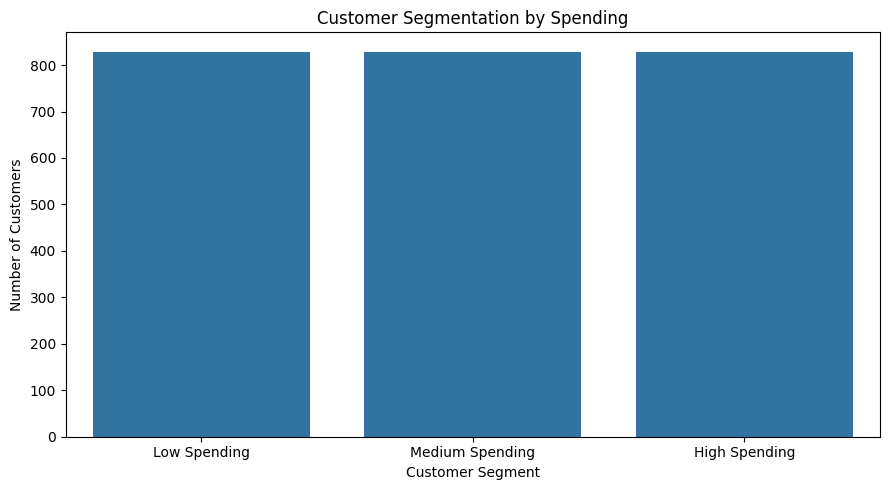

In [10]:

customer_analysis["Spending_Segment"] = pd.qcut(
    customer_analysis["Total_Spending"].rank(method="first"),
    q=3,
    labels=["Low Spending", "Medium Spending", "High Spending"]
)

segment_summary = (
    customer_analysis.groupby("Spending_Segment", observed=False)
    .agg(
        Number_of_Customers=("Customer_ID", "nunique"),
        Total_Spending=("Total_Spending", "sum"),
        Average_Spending=("Total_Spending", "mean")
    )
    .reset_index()
)

display(segment_summary.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=segment_summary,
    x="Spending_Segment",
    y="Number_of_Customers"
)

plt.title("Customer Segmentation by Spending")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


,Category,Total_Revenue,Total_Quantity,Unique_Customers
1,Electronics,1.960957e+08,7101,1790
2,Furniture,3.314933e+07,3489,1135
0,Accessories,2.563792e+07,9197,2024
5,Office,1.940468e+07,1712,657
6,Storage,1.349519e+07,1762,673
4,Networking,6.837255e+06,1790,681
3,Lifestyle,3.764906e+06,1883,725


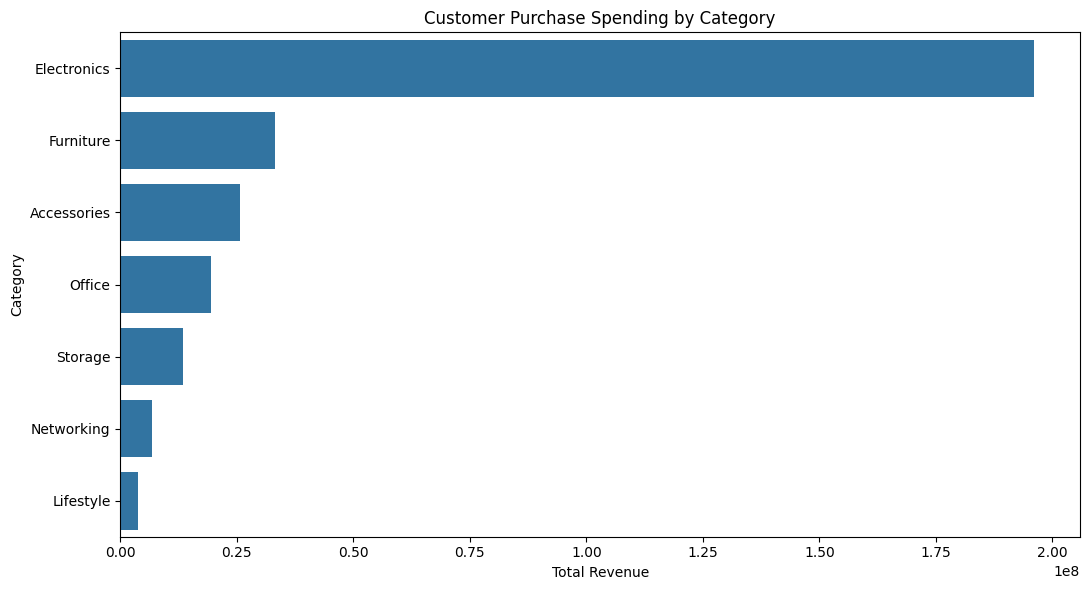

In [11]:

category_analysis = (
    sales_df.groupby("Category")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Customers=("Customer_ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

display(category_analysis.round(2))

plt.figure(figsize=(11, 6))
sns.barplot(
    data=category_analysis,
    x="Total_Revenue",
    y="Category"
)

plt.title("Customer Purchase Spending by Category")
plt.xlabel("Total Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


In [12]:

total_customers = sales_df["Customer_ID"].nunique()
total_orders = sales_df["Order_ID"].nunique()
total_revenue = sales_df["Revenue"].sum()
total_quantity = sales_df["Quantity"].sum()

average_customer_spending = (
    customer_analysis["Total_Spending"].mean()
)

average_order_value = total_revenue / total_orders

print("Total Unique Customers:", total_customers)
print("Total Unique Orders:", total_orders)
print(f"Total Revenue: {total_revenue:,.2f}")
print("Total Quantity Sold:", total_quantity)
print(f"Average Customer Spending: {average_customer_spending:,.2f}")
print(f"Average Order Value: {average_order_value:,.2f}")


Total Unique Customers: 2486
Total Unique Orders: 12000
Total Revenue: 298,385,016.59
Total Quantity Sold: 26934
Average Customer Spending: 120,026.15
Average Order Value: 24,865.42


In [13]:

top_customer = customer_analysis.iloc[0]
top_product = product_analysis.sort_values(
    "Total_Quantity", ascending=False
).iloc[0]
top_category = category_analysis.sort_values(
    "Total_Revenue", ascending=False
).iloc[0]
top_month = monthly_analysis.loc[
    monthly_analysis["Total_Revenue"].idxmax()
]
top_segment = segment_summary.loc[
    segment_summary["Total_Spending"].idxmax()
]

print("========== CUSTOMER PURCHASE INSIGHTS ==========")

print(
    f"Highest-spending customer: {top_customer['Customer_ID']} "
    f"with spending of {top_customer['Total_Spending']:,.2f}"
)

print(
    f"Most popular product by quantity: {top_product['Product']} "
    f"with {top_product['Total_Quantity']} units sold"
)

print(
    f"Top revenue category: {top_category['Category']} "
    f"with revenue of {top_category['Total_Revenue']:,.2f}"
)

print(
    f"Highest-revenue month: {top_month['Year_Month']} "
    f"with revenue of {top_month['Total_Revenue']:,.2f}"
)

print(
    f"Highest-contributing spending segment: {top_segment['Spending_Segment']}"
)

print("================================================")


========== CUSTOMER PURCHASE INSIGHTS ==========
Highest-spending customer: CUST10001 with spending of 131,712.51
Most popular product by quantity: Power Bank with 1911 units sold
Top revenue category: Electronics with revenue of 196,095,721.24
Highest-revenue month: 2026-08 with revenue of 17,062,844.70
Highest-contributing spending segment: High Spending


In [14]:

customer_analysis.to_csv("customer_analysis.csv", index=False)
product_analysis.to_csv("product_analysis.csv", index=False)
monthly_analysis.to_csv("monthly_analysis.csv", index=False)
frequency_analysis.to_csv("purchase_frequency.csv", index=False)
segment_summary.to_csv("customer_segments.csv", index=False)
category_analysis.to_csv("category_analysis.csv", index=False)

print("All analysis files exported successfully!")


All analysis files exported successfully!
